# Building Energy Efficiency Prediction

768 simulated buildings (Ecotect) varying shape, glazing, orientation and size. Predict the **heating load** — the energy a building needs to stay warm — from its design alone. Architects use models like this to make buildings cheaper to heat before they are built.


In [1]:
import io, urllib.request, zipfile
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=120) as r:
        return r.read()
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

raw = download('https://archive.ics.uci.edu/static/public/242/energy+efficiency.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.xlsx')][0]
df = pd.read_excel(io.BytesIO(zf.read(name)))
df.columns = ['relative_compactness', 'surface_area', 'wall_area', 'roof_area', 'overall_height', 'orientation', 'glazing_area', 'glazing_distribution', 'heating_load', 'cooling_load']
print(df.shape)
df.head()

/home/hatch/workspace/.pip-tmp/ipykernel_7198/3135576480.py:19: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  df = pd.read_excel(io.BytesIO(zf.read(name)))


(768, 10)


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [2]:
X = df.drop(columns=['heating_load', 'cooling_load']); y = df['heating_load']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
for name_m, m in [('Random Forest', rf), ('Linear', lin)]:
    p = m.predict(Xte)
    print(f'{name_m:15s} R2 {r2_score(yte, p):.3f}  MAE {mean_absolute_error(yte, p):.2f}')

Random Forest   R2 0.998  MAE 0.33
Linear          R2 0.915  MAE 2.18


relative_compactness    0.508507
surface_area            0.144559
roof_area               0.119624
overall_height          0.099734
glazing_area            0.075677
wall_area               0.036593
glazing_distribution    0.014496
orientation             0.000809
dtype: float64


<Axes: title={'center': 'What drives heating load?'}>

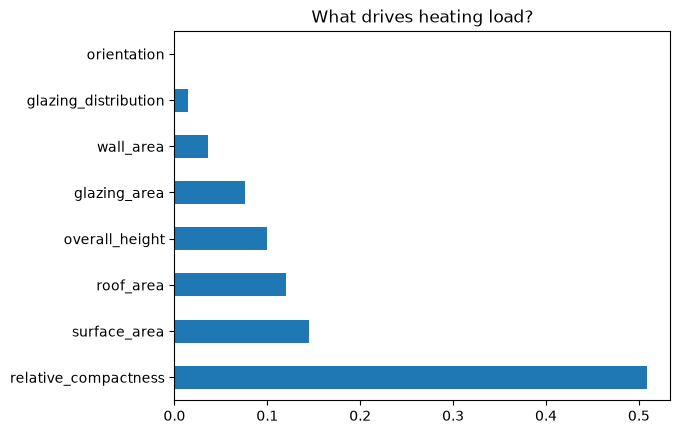

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='What drives heating load?')